
# Used Car Price Prediction Using Artificial Neural Network (ANN)

## 3. Model Training

### Objective
This notebook develops and compares two regression models for predicting used-car prices in the Indian market.

### Models
1. **Linear Regression:** A baseline model that estimates price using a linear relationship between the input features and the target.
2. **Artificial Neural Network (ANN):** A multilayer perceptron regressor (`MLPRegressor`) that can learn nonlinear relationships between vehicle characteristics and prices.

### Evaluation Approach
Both models will use the same training and test sets. Missing-value imputation, categorical encoding, and numerical scaling will be fitted on training data only to prevent data leakage.

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)



## 1. Library Imports and Configuration


In [23]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Project configuration
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "car_details_cleaned.csv"
)

TARGET_COLUMN = "price"
TEST_SIZE = 0.20
RANDOM_STATE = 42

print("Libraries imported successfully.")
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Libraries imported successfully.
Project root: /Users/abhisheksharma/code/Projects/used_car_price_prediction
Dataset path: /Users/abhisheksharma/code/Projects/used_car_price_prediction/data/processed/car_details_cleaned.csv
Dataset exists: True



## 2. Load Dataset and Split into Training and Testing Sets


In [24]:
# Load the cleaned dataset.
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

# Separate input features (X) and target (y).
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Split the dataset before fitting any preprocessing transformations.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print("\nTRAIN-TEST SPLIT")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target summary:")
display(y_train.describe())

print("\nTesting target summary:")
display(y_test.describe())


Dataset loaded successfully.
Dataset shape: (2059, 20)

Feature matrix shape: (2059, 19)
Target vector shape: (2059,)

TRAIN-TEST SPLIT
Training records: 1647
Testing records: 412

Training target summary:


count    1.647000e+03
mean     1.696655e+06
std      2.360649e+06
min      4.900000e+04
25%      4.775000e+05
50%      8.250000e+05
75%      1.950000e+06
max      2.750000e+07
Name: price, dtype: float64


Testing target summary:


count    4.120000e+02
mean     1.728323e+06
std      2.646371e+06
min      1.300000e+05
25%      4.950000e+05
50%      8.375000e+05
75%      1.850000e+06
max      3.500000e+07
Name: price, dtype: float64


## 3. Identify Numerical and Categorical Features


In [25]:
# Identify numerical and categorical input features.
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# Confirm that every input feature has been classified.
classified_features = set(numerical_features) | set(categorical_features)

assert classified_features == set(X_train.columns), (
    "Some features were not classified as numerical or categorical."
)

assert not (
    set(numerical_features) & set(categorical_features)
), "A feature was classified into both groups."

print("\nFeature classification validated successfully.")


Numerical features: 10
['year', 'kilometer', 'engine', 'max_power', 'max_torque', 'length', 'width', 'height', 'seating_capacity', 'fuel_tank_capacity']

Categorical features: 9
['make', 'model', 'fuel_type', 'transmission', 'location', 'color', 'owner', 'seller_type', 'drivetrain']

Feature classification validated successfully.



## 4. Build the Feature Preprocessing Pipeline


In [26]:
# Numerical preprocessing:
# 1. Replace missing values with the training-set median.
# 2. Standardize features for model training.
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Categorical preprocessing:
# 1. Replace missing values with the most frequent training-set category.
# 2. Convert categories into numerical indicator columns.
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
            ),
        ),
    ]
)

# Apply the appropriate workflow to each feature group.
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer, numerical_features),
        ("categorical", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

print("Preprocessing pipeline created successfully.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully.
Numerical features: 10
Categorical features: 9



## 5. Train the Linear Regression Baseline


In [27]:
# Create a complete pipeline for Linear Regression.
linear_regression_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]
)

# Fit the pipeline using training data only.
linear_regression_pipeline.fit(X_train, y_train)

# Predict prices for the unseen test data.
y_pred_linear = linear_regression_pipeline.predict(X_test)

print("Linear Regression trained successfully.")
print("Number of test predictions:", len(y_pred_linear))

print("\nSample predictions:")
linear_prediction_preview = pd.DataFrame({
    "actual_price": y_test.iloc[:10].values,
    "predicted_price": y_pred_linear[:10],
})

display(linear_prediction_preview)

Linear Regression trained successfully.
Number of test predictions: 412

Sample predictions:


,actual_price,predicted_price
0,4800000,1.022035e+07
1,825000,8.549578e+05
2,695000,-3.018316e+06
3,950000,1.301198e+06
4,819999,6.777867e+05
5,310000,8.179826e+02
6,1000000,-1.751452e+06
7,1998999,-1.012455e+06
8,850000,1.612737e+07
9,3950000,2.007731e+06



## 6. Train the Artificial Neural Network (ANN)


In [28]:
# Create the ANN pipeline.
ann_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            MLPRegressor(
                hidden_layer_sizes=(128, 64),
                activation="relu",
                solver="adam",
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=500,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=20,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Train the ANN using training data only.
ann_pipeline.fit(X_train, y_train)

# Predict prices for the unseen test set.
y_pred_ann = ann_pipeline.predict(X_test)

print("ANN trained successfully.")
print("Number of test predictions:", len(y_pred_ann))

# Display sample predictions.
ann_prediction_preview = pd.DataFrame({
    "actual_price": y_test.iloc[:10].values,
    "predicted_price": y_pred_ann[:10],
})

display(ann_prediction_preview)

# Report the number of training iterations.
ann_model = ann_pipeline.named_steps["model"]
print("\nANN training iterations:", ann_model.n_iter_)
print("Final training loss:", ann_model.loss_)

ANN trained successfully.
Number of test predictions: 412


/Users/abhisheksharma/code/Projects/used_car_price_prediction/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,actual_price,predicted_price
0,4800000,4.521979e+06
1,825000,7.577054e+05
2,695000,7.993547e+04
3,950000,1.316210e+06
4,819999,8.010735e+05
5,310000,3.956419e+02
6,1000000,2.102689e+06
7,1998999,2.379769e+06
8,850000,2.320685e+06
9,3950000,4.557711e+06



ANN training iterations: 500
Final training loss: 855709143835.4364



## 7. Evaluate and Compare Model Performance

The models will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² on the same test set.


In [29]:
def calculate_regression_metrics(
    y_true,
    y_pred,
    model_name,
) -> dict:
    """Calculate standard regression evaluation metrics."""
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


# Evaluate both models on the same test data.
linear_metrics = calculate_regression_metrics(
    y_test,
    y_pred_linear,
    "Linear Regression",
)

ann_metrics = calculate_regression_metrics(
    y_test,
    y_pred_ann,
    "ANN (MLPRegressor)",
)

# Create a comparison table.
results_df = pd.DataFrame([
    linear_metrics,
    ann_metrics,
])

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "MAE": "₹{:,.2f}",
        "RMSE": "₹{:,.2f}",
        "R2": "{:.4f}",
    })
)

MODEL PERFORMANCE COMPARISON


,model,MAE,RMSE,R2
0,Linear Regression,"₹1,830,941.44","₹4,240,733.15",-1.5742
1,ANN (MLPRegressor),"₹708,097.33","₹1,683,744.40",0.5942



## 8. Actual vs Predicted Price Visualization


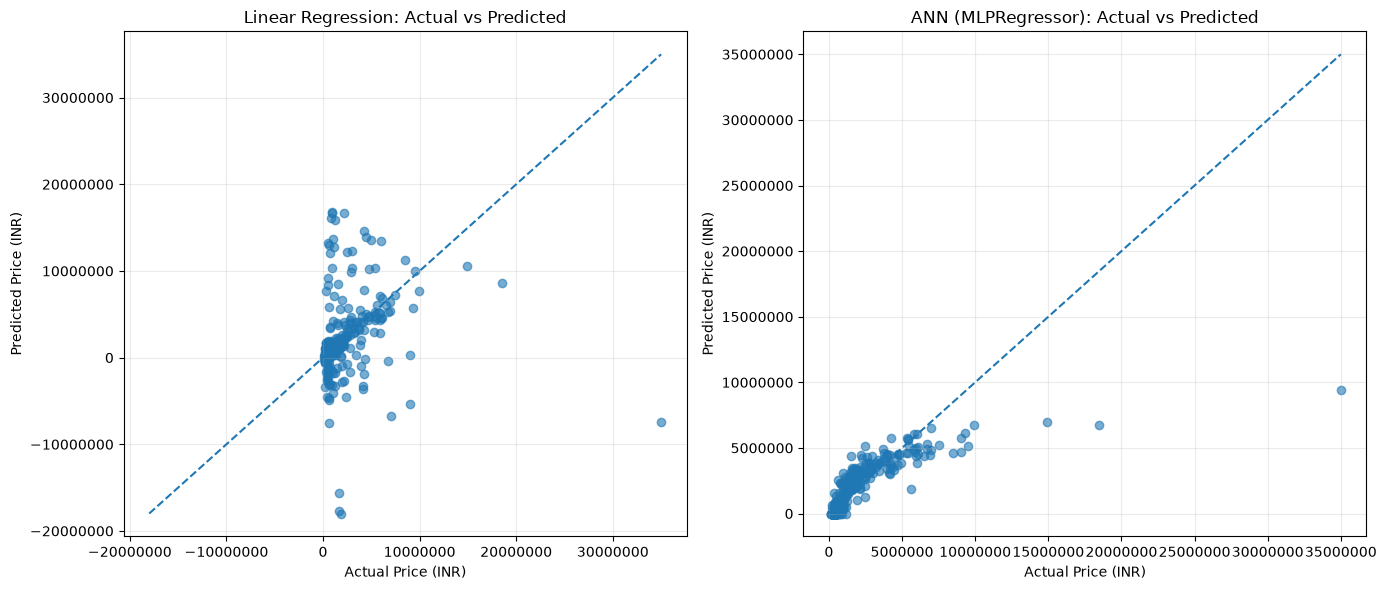

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prediction_sets = [
    ("Linear Regression", y_pred_linear, axes[0]),
    ("ANN (MLPRegressor)", y_pred_ann, axes[1]),
]

for model_name, predictions, ax in prediction_sets:
    ax.scatter(
        y_test,
        predictions,
        alpha=0.6,
    )

    # Reference line: perfect predictions lie on this line.
    lower_bound = min(y_test.min(), predictions.min())
    upper_bound = max(y_test.max(), predictions.max())

    ax.plot(
        [lower_bound, upper_bound],
        [lower_bound, upper_bound],
        linestyle="--",
    )

    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual Price (INR)")
    ax.set_ylabel("Predicted Price (INR)")
    ax.ticklabel_format(style="plain", axis="both")
    ax.grid(alpha=0.25)

plt.tight_layout()
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "original_ann_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Error Analysis

In [31]:
# Compare actual and predicted prices for the ANN
error_analysis = pd.DataFrame({
    "actual_price": y_test.values,
    "predicted_price": y_pred_ann,
})

error_analysis["absolute_error"] = (
    error_analysis["actual_price"]
    - error_analysis["predicted_price"]
).abs()

error_analysis["percentage_error"] = (
    error_analysis["absolute_error"]
    / error_analysis["actual_price"]
) * 100

# Display the 10 predictions with the largest absolute errors
largest_errors = error_analysis.sort_values(
    by="absolute_error",
    ascending=False
).head(10)

display(
    largest_errors.style.format({
        "actual_price": "₹{:,.0f}",
        "predicted_price": "₹{:,.0f}",
        "absolute_error": "₹{:,.0f}",
        "percentage_error": "{:.2f}%"
    })
)

,actual_price,predicted_price,absolute_error,percentage_error
405,"₹35,000,000","₹9,445,271","₹25,554,729",73.01%
75,"₹18,500,000","₹6,733,072","₹11,766,928",63.61%
106,"₹14,900,000","₹6,951,161","₹7,948,839",53.35%
279,"₹9,500,000","₹5,157,602","₹4,342,398",45.71%
45,"₹9,000,000","₹4,727,034","₹4,272,966",47.48%
309,"₹8,500,000","₹4,604,172","₹3,895,828",45.83%
409,"₹5,590,000","₹1,833,989","₹3,756,011",67.19%
13,"₹9,000,000","₹5,722,808","₹3,277,192",36.41%
260,"₹9,900,000","₹6,740,916","₹3,159,084",31.91%
174,"₹9,300,000","₹6,143,717","₹3,156,283",33.94%


## 9. ANN with Log-Transformed Target

The target variable, car price, has a wide range and a right-skewed distribution. To investigate whether this affects model performance, we train another ANN using the natural logarithm of price (`log1p`). Predictions are converted back to the original price scale using `expm1` before calculating evaluation metrics.

This experiment allows us to compare the original ANN against an ANN trained on log-transformed prices using the same train-test split.

In [32]:
from sklearn.base import clone

# Transform the target prices
y_train_log = np.log1p(y_train)

# Create a separate ANN pipeline
ann_log_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=RANDOM_STATE,
    )),
])

# Train on log-transformed prices
ann_log_pipeline.fit(X_train, y_train_log)

# Predict log prices, then convert back to rupees
y_pred_ann_log = np.expm1(
    ann_log_pipeline.predict(X_test)
)

# Evaluate on the original price scale
log_ann_metrics = calculate_regression_metrics(
    y_test,
    y_pred_ann_log,
    "ANN (Log-Transformed Target)"
)

print("Log-transformed ANN trained successfully.")
print("Training iterations:",
      ann_log_pipeline.named_steps["model"].n_iter_)
display(pd.DataFrame([log_ann_metrics]).style.format({
    "MAE": "₹{:,.2f}",
    "RMSE": "₹{:,.2f}",
    "R2": "{:.4f}",
}))

Log-transformed ANN trained successfully.
Training iterations: 99


,model,MAE,RMSE,R2
0,ANN (Log-Transformed Target),"₹510,533.47","₹1,158,513.52",0.8079


### Actual vs Predicted: Log-Transformed ANN

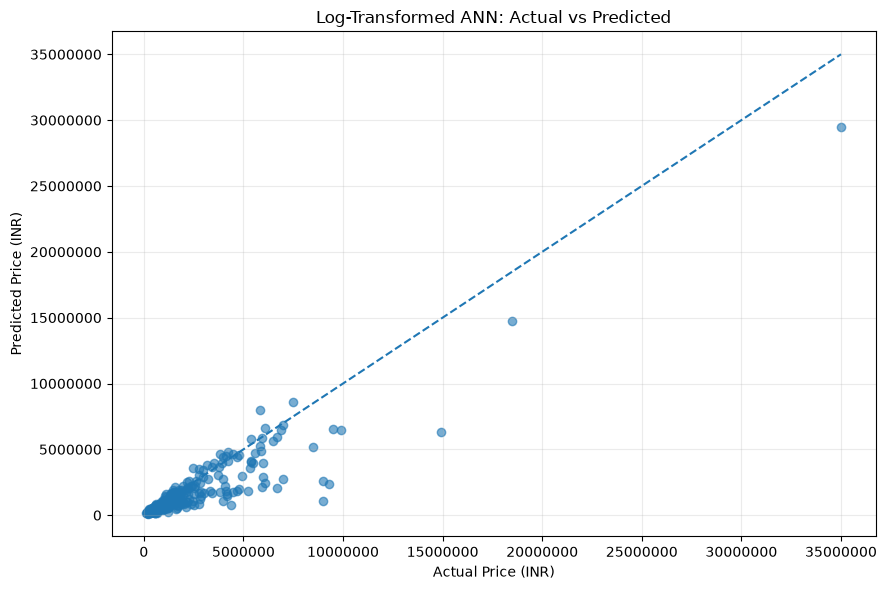

In [45]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    y_test,
    y_pred_ann_log,
    alpha=0.6
)

lower_bound = min(y_test.min(), y_pred_ann_log.min())
upper_bound = max(y_test.max(), y_pred_ann_log.max())

ax.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    linestyle="--"
)

ax.set_title("Log-Transformed ANN: Actual vs Predicted")
ax.set_xlabel("Actual Price (INR)")
ax.set_ylabel("Predicted Price (INR)")
ax.ticklabel_format(style="plain", axis="both")
ax.grid(alpha=0.25)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "log_ann_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Price Segment Evaluation

In [34]:
# Compare ANN performance across actual-price segments
segment_results = pd.DataFrame({
    "actual_price": y_test.values,
    "original_ann_prediction": y_pred_ann,
    "log_ann_prediction": y_pred_ann_log,
})

segment_results["price_segment"] = pd.cut(
    segment_results["actual_price"],
    bins=[0, 1_000_000, 3_000_000, float("inf")],
    labels=["Budget (≤ ₹10 lakh)",
            "Mid-range (₹10–30 lakh)",
            "Premium (> ₹30 lakh)"],
    include_lowest=True,
)

rows = []

for segment, group in segment_results.groupby(
    "price_segment", observed=True
):
    rows.append({
        "price_segment": segment,
        "number_of_cars": len(group),
        "original_ann_mae": mean_absolute_error(
            group["actual_price"],
            group["original_ann_prediction"],
        ),
        "log_ann_mae": mean_absolute_error(
            group["actual_price"],
            group["log_ann_prediction"],
        ),
    })

segment_metrics = pd.DataFrame(rows)

display(segment_metrics.style.format({
    "original_ann_mae": "₹{:,.0f}",
    "log_ann_mae": "₹{:,.0f}",
}))

,price_segment,number_of_cars,original_ann_mae,log_ann_mae
0,Budget (≤ ₹10 lakh),235,"₹350,807","₹115,463"
1,Mid-range (₹10–30 lakh),116,"₹825,031","₹486,137"
2,Premium (> ₹30 lakh),61,"₹1,862,178","₹2,078,919"


### Premium Car Error Investigation

In [35]:
# Inspect premium cars with the largest log-ANN errors
premium_analysis = segment_results[
    segment_results["actual_price"] > 3_000_000
].copy()

premium_analysis["absolute_error"] = (
    premium_analysis["actual_price"]
    - premium_analysis["log_ann_prediction"]
).abs()

# Restore the original test-set row positions
premium_analysis["test_row_position"] = premium_analysis.index

premium_analysis = premium_analysis.sort_values(
    by="absolute_error",
    ascending=False,
)

# Retrieve the corresponding vehicle details from X_test
premium_details = X_test.iloc[
    premium_analysis["test_row_position"].to_numpy()
][["make", "model", "year", "kilometer", "fuel_type", "transmission"]].reset_index(drop=True)

premium_analysis = premium_analysis.reset_index(drop=True)

premium_inspection = pd.concat(
    [
        premium_details,
        premium_analysis[
            ["actual_price", "log_ann_prediction", "absolute_error"]
        ],
    ],
    axis=1,
)

display(premium_inspection.head(15).style.format({
    "actual_price": "₹{:,.0f}",
    "log_ann_prediction": "₹{:,.0f}",
    "absolute_error": "₹{:,.0f}",
}))

,make,model,year,kilometer,fuel_type,transmission,actual_price,log_ann_prediction,absolute_error
0,Porsche,Cayenne Base,2021,7534,Petrol,Automatic,"₹14,900,000","₹6,316,377","₹8,583,623"
1,Maserati,Levante Diesel,2017,40000,Diesel,Automatic,"₹9,000,000","₹1,088,211","₹7,911,789"
2,Porsche,911 Carrera 4,2019,9000,Petrol,Automatic,"₹9,300,000","₹2,388,614","₹6,911,386"
3,Porsche,718 Cayman [2017-2020],2017,7000,Petrol,Automatic,"₹9,000,000","₹2,611,881","₹6,388,119"
4,Ferrari,488 GTB,2018,9500,Petrol,Automatic,"₹35,000,000","₹29,489,280","₹5,510,720"
5,BMW,X3 xDrive30i M Sport,2022,18223,Petrol,Automatic,"₹6,680,000","₹2,094,918","₹4,585,082"
6,Mercedes-Benz,C-Coupe 43 AMG 4MATIC,2020,19000,Petrol,Automatic,"₹7,000,000","₹2,776,697","₹4,223,303"
7,Land Rover,Evoque SE R-Dynamic,2021,35000,Diesel,Automatic,"₹5,950,000","₹2,173,091","₹3,776,909"
8,Mercedes-Benz,S-Class S 350D [2018-2020],2021,5000,Diesel,Automatic,"₹18,500,000","₹14,723,659","₹3,776,341"
9,Mercedes-Benz,C-Class C220d Progressive,2022,500,Diesel,Automatic,"₹6,100,000","₹2,466,350","₹3,633,650"


### Luxury Brand Representation in Training Data

In [36]:
# Examine premium brands represented in the training set
premium_brands = [
    "Porsche",
    "Maserati",
    "Ferrari",
    "Lamborghini",
    "Bentley",
    "Rolls-Royce",
]

training_brand_summary = (
    X_train.assign(actual_price=y_train.values)
    .groupby("make")
    .agg(
        training_records=("actual_price", "size"),
        median_price=("actual_price", "median"),
        maximum_price=("actual_price", "max"),
    )
    .reindex(premium_brands)
    .dropna(subset=["training_records"])
    .sort_values("training_records", ascending=False)
)

display(training_brand_summary.style.format({
    "median_price": "₹{:,.0f}",
    "maximum_price": "₹{:,.0f}",
}))

,training_records,median_price,maximum_price
make,,,
Porsche,9.000000,"₹7,500,000","₹16,200,000"
Rolls-Royce,3.000000,"₹20,000,000","₹20,000,000"
Lamborghini,1.000000,"₹24,000,000","₹24,000,000"


## 10. Random Forest Regression

In [37]:
from sklearn.ensemble import RandomForestRegressor

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

# Train on the original price scale
random_forest_pipeline.fit(X_train, y_train)

# Predict prices
y_pred_rf = random_forest_pipeline.predict(X_test)

# Evaluate predictions
rf_metrics = calculate_regression_metrics(
    y_test,
    y_pred_rf,
    "Random Forest",
)

print("Random Forest trained successfully.")
display(pd.DataFrame([rf_metrics]).style.format({
    "MAE": "₹{:,.2f}",
    "RMSE": "₹{:,.2f}",
    "R2": "{:.4f}",
}))

Random Forest trained successfully.


,model,MAE,RMSE,R2
0,Random Forest,"₹306,199.29","₹1,176,929.73",0.8017


### Random Forest Price Segment Evaluation

In [38]:
rf_segment_data = pd.DataFrame({
    "actual_price": y_test.values,
    "rf_prediction": y_pred_rf,
    "log_ann_prediction": y_pred_ann_log,
})

rf_segment_data["price_segment"] = pd.cut(
    rf_segment_data["actual_price"],
    bins=[0, 1_000_000, 3_000_000, float("inf")],
    labels=[
        "Budget (≤ ₹10 lakh)",
        "Mid-range (₹10–30 lakh)",
        "Premium (> ₹30 lakh)",
    ],
    include_lowest=True,
)

rf_segment_results = []

for segment, group in rf_segment_data.groupby(
    "price_segment", observed=True
):
    rf_segment_results.append({
        "price_segment": segment,
        "number_of_cars": len(group),
        "log_ann_mae": mean_absolute_error(
            group["actual_price"],
            group["log_ann_prediction"],
        ),
        "random_forest_mae": mean_absolute_error(
            group["actual_price"],
            group["rf_prediction"],
        ),
    })

rf_segment_metrics = pd.DataFrame(rf_segment_results)

display(rf_segment_metrics.style.format({
    "log_ann_mae": "₹{:,.0f}",
    "random_forest_mae": "₹{:,.0f}",
}))

,price_segment,number_of_cars,log_ann_mae,random_forest_mae
0,Budget (≤ ₹10 lakh),235,"₹115,463","₹82,617"
1,Mid-range (₹10–30 lakh),116,"₹486,137","₹263,942"
2,Premium (> ₹30 lakh),61,"₹2,078,919","₹1,247,901"


### Actual vs Predicted: Random Forest

Plot saved to: /Users/abhisheksharma/code/Projects/used_car_price_prediction/reports/figures/random_forest_actual_vs_predicted.png


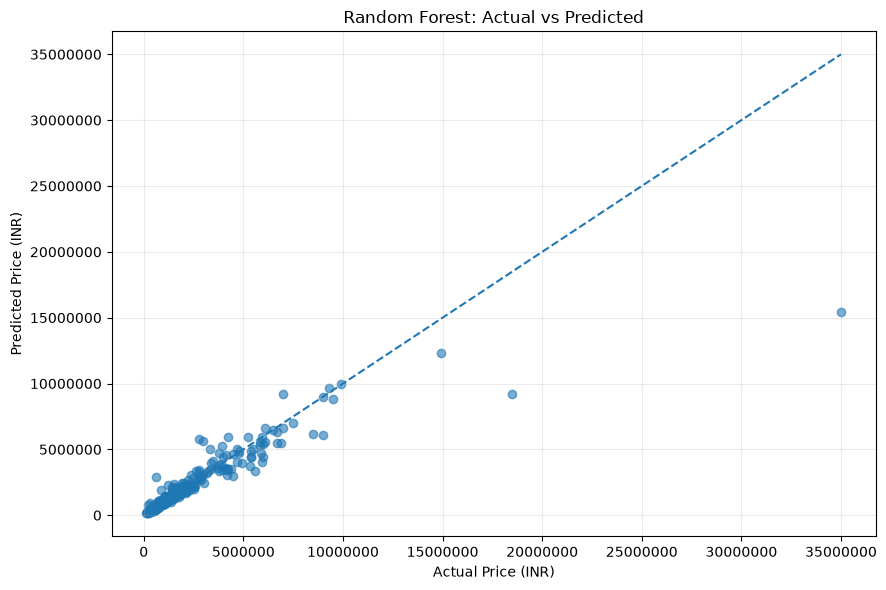

In [39]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    y_test,
    y_pred_rf,
    alpha=0.6,
)

lower_bound = min(y_test.min(), y_pred_rf.min())
upper_bound = max(y_test.max(), y_pred_rf.max())

ax.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    linestyle="--",
)

ax.set_title("Random Forest: Actual vs Predicted")
ax.set_xlabel("Actual Price (INR)")
ax.set_ylabel("Predicted Price (INR)")
ax.ticklabel_format(style="plain", axis="both")
ax.grid(alpha=0.25)

plt.tight_layout()

# Save the figure for the project report
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "random_forest_actual_vs_predicted.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print("Plot saved to:", figure_path)
plt.show()

### Final Model Comparison

In [40]:
final_model_comparison = pd.DataFrame([
    linear_metrics,
    ann_metrics,
    log_ann_metrics,
    rf_metrics,
])

final_model_comparison = final_model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

display(final_model_comparison.style.format({
    "MAE": "₹{:,.2f}",
    "RMSE": "₹{:,.2f}",
    "R2": "{:.4f}",
}))

,model,MAE,RMSE,R2
0,Random Forest,"₹306,199.29","₹1,176,929.73",0.8017
1,ANN (Log-Transformed Target),"₹510,533.47","₹1,158,513.52",0.8079
2,ANN (MLPRegressor),"₹708,097.33","₹1,683,744.40",0.5942
3,Linear Regression,"₹1,830,941.44","₹4,240,733.15",-1.5742


### Saving Model Comparison Results

In [41]:
# Create the metrics output directory
metrics_dir = PROJECT_ROOT / "reports" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

# Save the final comparison as a CSV file
metrics_path = metrics_dir / "model_comparison.csv"

final_model_comparison.to_csv(
    metrics_path,
    index=False,
)

print("Model comparison saved successfully.")
print("File path:", metrics_path)
print("File exists:", metrics_path.exists())

Model comparison saved successfully.
File path: /Users/abhisheksharma/code/Projects/used_car_price_prediction/reports/metrics/model_comparison.csv
File exists: True


### Saving the Trained Random Forest Model

In [42]:
import joblib

# Create the models directory
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Define the model output path
model_path = models_dir / "random_forest_pipeline.joblib"

# Save the complete trained pipeline
joblib.dump(random_forest_pipeline, model_path)

print("Random Forest pipeline saved successfully.")
print("File path:", model_path)
print("File exists:", model_path.exists())
print("File size (KB):", round(model_path.stat().st_size / 1024, 2))

Random Forest pipeline saved successfully.
File path: /Users/abhisheksharma/code/Projects/used_car_price_prediction/models/random_forest_pipeline.joblib
File exists: True
File size (KB): 19287.36


### Verifying the Saved Model

In [43]:
import joblib
import numpy as np

# Load the saved pipeline
loaded_model = joblib.load(model_path)

# Generate predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare with predictions from the original pipeline
predictions_match = np.allclose(
    y_pred_rf,
    loaded_predictions,
)

print("Saved model loaded successfully.")
print("Number of predictions:", len(loaded_predictions))
print("Predictions match original model:", predictions_match)

assert predictions_match, (
    "Loaded model predictions do not match the original predictions."
)

print("Model verification passed.")

Saved model loaded successfully.
Number of predictions: 412
Predictions match original model: True
Model verification passed.
